# Label Poisoning Studies

In [2]:
import sys
import os
import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split

# Add parent directory to path to access the src module
sys.path.append(os.path.abspath('..')) 

from src.data_loader import load_svhn_data
from src.features import extract_flattened, extract_pca, extract_resnet_embeddings
from src.pytorch_mlp import MLPClassifier

# 1. Load SVHN Dataset
print("--- Loading SVHN Dataset ---")
X_train_raw, y_train, X_test_raw, y_test = load_svhn_data(
    data_dir="../data/raw", 
    random_state=42, 
    normalize=True
)

# 2. Extract Features
print("\n--- Extracting Flattened Features ---")
X_train_flat, X_test_flat = extract_flattened(X_train_raw, X_test_raw, standardize=True)

print("--- Extracting PCA Features (53 comp.) ---")
X_train_pca, X_test_pca, _ = extract_pca(X_train_flat, X_test_flat, n_components=53, random_state=42)

# Create Validation Set
X_train_final, X_val_final, y_train_final, y_val_final = train_test_split(
    X_train_pca, y_train, 
    test_size=5000, 
    stratify=y_train, 
    random_state=42
)

noise_levels = [0.0, 0.1, 0.2, 0.4, 0.6]

--- Loading SVHN Dataset ---
Loading SVHN Dataset
Dataset Loaded. Train: (73257, 3, 32, 32), Test: (26032, 3, 32, 32)

--- Extracting Flattened Features ---
--- Extracting PCA Features (53 comp.) ---


## Optimal MLP Label Poisoning

Starting Label Poisoning (Noise Robustness) Experiment...
-----------------------------------------------------------------
Training with 0% label noise...
Using Class Weights: [1.4806 0.5285 0.6921 0.8622 0.9823 1.0645 1.2792 1.3094 1.452  1.5724]
Epoch 01/60 | LR: 0.009891 | Train Loss: 1.3801 | Val F1: 0.6462
Epoch 02/60 | LR: 0.009568 | Train Loss: 1.0861 | Val F1: 0.6447
Epoch 03/60 | LR: 0.009045 | Train Loss: 1.0083 | Val F1: 0.6575
Epoch 04/60 | LR: 0.008346 | Train Loss: 0.9617 | Val F1: 0.6990
Epoch 05/60 | LR: 0.007500 | Train Loss: 0.9199 | Val F1: 0.7216
Epoch 06/60 | LR: 0.006545 | Train Loss: 0.8793 | Val F1: 0.7244
Epoch 07/60 | LR: 0.005523 | Train Loss: 0.8368 | Val F1: 0.7270
Epoch 08/60 | LR: 0.004477 | Train Loss: 0.7959 | Val F1: 0.7458
Epoch 09/60 | LR: 0.003455 | Train Loss: 0.7504 | Val F1: 0.7634
Epoch 10/60 | LR: 0.002500 | Train Loss: 0.7049 | Val F1: 0.7637
Epoch 11/60 | LR: 0.001654 | Train Loss: 0.6607 | Val F1: 0.7892
Epoch 12/60 | LR: 0.000955 | Train L

,Noise Level (%),Clean Test F1 (%),Fit Time (sec)
0,0,79.59,272.434
1,10,77.67,446.621
2,20,76.87,396.221
3,40,71.91,261.389
4,60,56.27,191.078


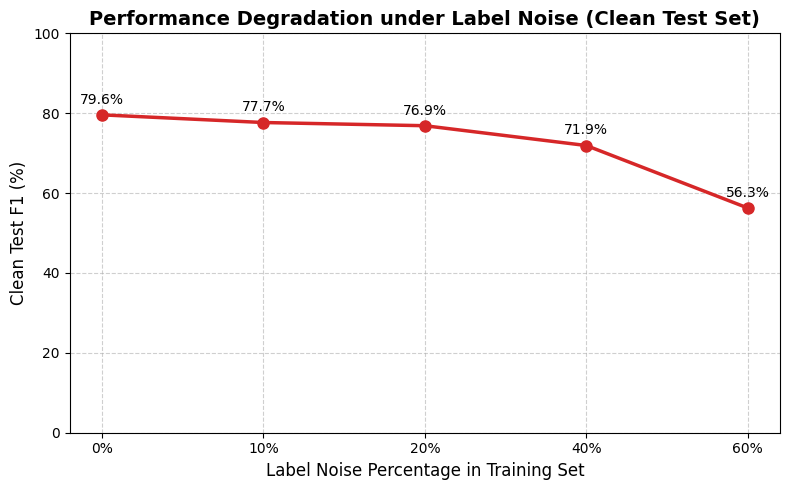

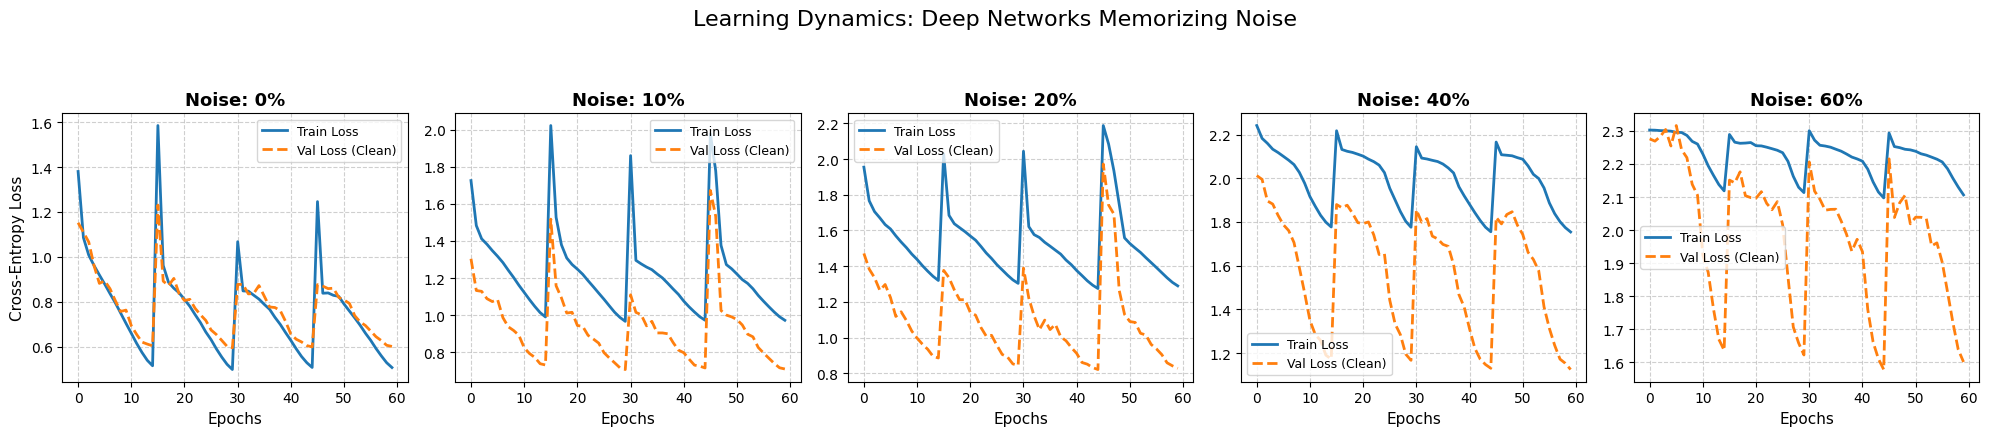

In [3]:
results_noise = []
histories_noise = {}


print("Starting Label Poisoning (Noise Robustness) Experiment...\n" + "-"*65)

for noise in noise_levels:
    print(f"Training with {int(noise*100)}% label noise...")
    
    # 1. Inject Noise (Label Poisoning)
    y_train_noisy = copy.deepcopy(y_train_final)
    if noise > 0.0:
        n_samples = len(y_train_final)
        n_noisy = int(noise * n_samples)
        
        # Select random indices to poison
        np.random.seed(42)
        noisy_indices = np.random.choice(n_samples, n_noisy, replace=False)
        
        # Replace with random labels from 0 to 9
        random_labels = np.random.randint(0, 10, n_noisy)
        y_train_noisy[noisy_indices] = random_labels

    # 2. Initialize Optimal MLP
    optimal_mlp = MLPClassifier(
        hidden_layers=[256, 128, 64],  
        activation='relu',
        learning_rate=0.01,
        weight_decay=0.001,
        epochs=60,                     
        T_0=15,
        batch_size=64,
        random_state=42,
        use_class_weights=True,       
        verbose=1                     
)
    
    # 3. Training (Using PCA 53 components for faster execution)
    t0_fit = time.time()
    optimal_mlp.fit(X=X_train_final, y=y_train_noisy,X_val=X_val_final, y_val=y_val_final)
    fit_time = time.time() - t0_fit
    
    # 4. Evaluation STRICTLY on the CLEAN Test Set
    y_pred_test = optimal_mlp.predict(X_test_pca)
    test_acc = f1_score(y_test, y_pred_test,average='macro') * 100
    
    print(f" -> Clean Test F1: {test_acc:6.2f}% | Fit Time: {fit_time:.2f}s")
    
    # Store training history for learning curves
    histories_noise[noise] = optimal_mlp.history_
    
    results_noise.append({
        'Noise Level (%)': int(noise * 100),
        'Clean Test F1 (%)': round(test_acc, 2),
        'Fit Time (sec)': round(fit_time, 3)
    })

# Display Results DataFrame
df_noise_results = pd.DataFrame(results_noise)
display(df_noise_results)

# --- Visualization 1: Performance Degradation on Clean Test Set ---
plt.figure(figsize=(8, 5))
x_labels = [str(int(n*100)) + '%' for n in noise_levels]
plt.plot(x_labels, df_noise_results['Clean Test F1 (%)'], 
         marker='o', color='#d62728', linewidth=2.5, markersize=8)

plt.title('Performance Degradation under Label Noise (Clean Test Set)', fontsize=14, fontweight='bold')
plt.xlabel('Label Noise Percentage in Training Set', fontsize=12)
plt.ylabel('Clean Test F1 (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.ylim(0, 100)

for i, txt in enumerate(df_noise_results['Clean Test F1 (%)']):
    plt.annotate(f"{txt:.1f}%", (i, df_noise_results['Clean Test F1 (%)'][i]), 
                 textcoords="offset points", xytext=(0, 8), ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# --- Visualization 2: Learning Curves (Memorizing Noise) ---
fig, axes = plt.subplots(nrows=1, ncols=len(noise_levels), figsize=(20, 4))

for ax, noise in zip(axes, noise_levels):
    history = histories_noise[noise]
    train_loss = history['train_loss']
    val_loss = history['val_loss']
    
    ax.plot(train_loss, label='Train Loss', color='#1f77b4', linewidth=2)
    ax.plot(val_loss, label='Val Loss (Clean)', color='#ff7f0e', linewidth=2, linestyle='--')
    
    ax.set_title(f'Noise: {int(noise*100)}%', fontsize=13, fontweight='bold')
    ax.set_xlabel('Epochs', fontsize=11)
    if noise == 0.0:
        ax.set_ylabel('Cross-Entropy Loss', fontsize=11)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(fontsize=9)

plt.suptitle('Learning Dynamics: Deep Networks Memorizing Noise', fontsize=16, y=1.08)
plt.tight_layout()
plt.show()